Image files found: 2185
Unreadable files: 0 []

Class counts:
 label
cancer        1184
non_cancer    1001

Top image sizes (w, h): [((280, 205), 69), ((960, 1280), 58), ((468, 1040), 36), ((720, 1280), 26), ((275, 183), 22)]

Exact-duplicate MD5 groups: 924
Near-duplicate pairs (pHash <= 4): 1462
Unique groups: 1094 of 2185 images | groups with >1 image: 905 | largest group: 9
Groups containing conflicting labels: 1

Saved C:\Users\Bhavana BV\Downloads\OncoLens\split.csv. Label map: {'cancer': 0, 'non_cancer': 1}

Split sizes:
 label  cancer  non_cancer   All
split                          
test      178         151   329
train     828         700  1528
val       178         150   328
All      1184        1001  2185

Split proportions: {'train': 0.699, 'test': 0.151, 'val': 0.15}
train/val: zero overlap OK (min pHash distance across splits = 6)
train/test: zero overlap OK (min pHash distance across splits = 8)
val/test: zero overlap OK (min pHash distance across splits = 14)


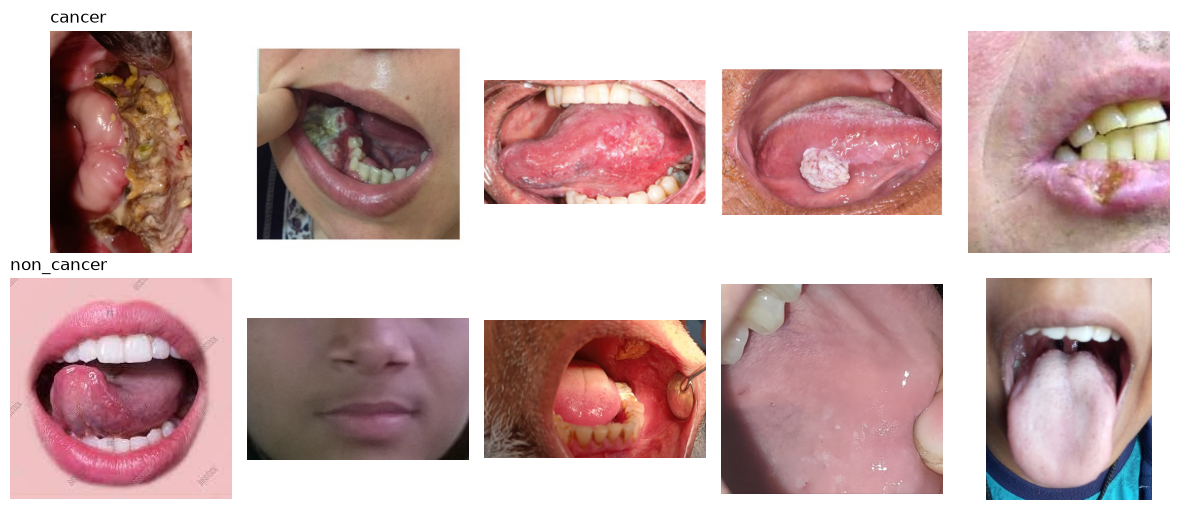


Step 02 done.


In [3]:
# %% Step 02: exploration + leakage-controlled group split
import hashlib
from collections import Counter
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import imagehash
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
PHASH_MAX_DIST = 4          # Hamming distance (of 64 bits) counted as near-duplicate
ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")
DATA = ROOT / "dataset"
SPLIT_CSV = ROOT / "split.csv"
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
for d in ["results", "figures", "checkpoints"]:
    (ROOT / d).mkdir(exist_ok=True)

if SPLIT_CSV.exists():
    # ---- split is frozen: load, never regenerate ----
    df = pd.read_csv(SPLIT_CSV)
    print(f"Loaded existing {SPLIT_CSV.name} ({len(df)} rows). Not regenerating.")
else:
    # ---- 1. scan + hash ----
    files = sorted(p for p in DATA.rglob("*") if p.suffix.lower() in EXTS)
    print(f"Image files found: {len(files)}")
    rows, bad = [], []
    for p in files:
        rel = p.relative_to(DATA)
        if len(rel.parts) < 2:
            raise SystemExit(f"{rel} is not inside a class subfolder. Paste your folder layout.")
        try:
            with Image.open(p) as im:
                im.load()
                w, h = im.size
                ph = str(imagehash.phash(im.convert("RGB")))
            rows.append(dict(path=rel.as_posix(), label=rel.parts[0], w=w, h=h,
                             md5=hashlib.md5(p.read_bytes()).hexdigest(), phash=ph))
        except Exception as e:
            bad.append((rel.as_posix(), repr(e)))
    df = pd.DataFrame(rows)
    print(f"Unreadable files: {len(bad)}", bad[:5])

    top = set(df.label.unique())
    if top & {"train", "val", "valid", "validation", "test"}:
        raise SystemExit(f"Top-level folders look like pre-made splits: {top}. Paste your layout.")

    # ---- 2. exploration ----
    print("\nClass counts:\n", df.label.value_counts().to_string())
    print("\nTop image sizes (w, h):", Counter(zip(df.w, df.h)).most_common(5))

    # ---- 3. duplicate groups: exact (MD5) + near (pHash) via union-find ----
    n = len(df)
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    for _, idx in df.groupby("md5").indices.items():
        for j in idx[1:]:
            union(idx[0], j)
    n_exact_groups = int((df.md5.value_counts() > 1).sum())

    bits = np.array([np.unpackbits(np.frombuffer(bytes.fromhex(h), dtype=np.uint8))
                     for h in df.phash], dtype=np.float32)
    D = 64 - (bits @ bits.T + (1 - bits) @ (1 - bits).T)       # pairwise Hamming
    near_pairs = np.argwhere(np.triu(D <= PHASH_MAX_DIST, k=1))
    for a, b in near_pairs:
        union(int(a), int(b))
    df["group"] = pd.factorize(np.array([find(i) for i in range(n)]))[0]   # FIXED

    gsize = df.group.value_counts()
    print(f"\nExact-duplicate MD5 groups: {n_exact_groups}")
    print(f"Near-duplicate pairs (pHash <= {PHASH_MAX_DIST}): {len(near_pairs)}")
    print(f"Unique groups: {df.group.nunique()} of {n} images | "
          f"groups with >1 image: {(gsize > 1).sum()} | largest group: {gsize.max()}")
    conflict = df.groupby("group").label.nunique()
    print(f"Groups containing conflicting labels: {(conflict > 1).sum()}")

    # ---- 4. stratified group split 70/15/15 (20 buckets: 14 / 3 / 3) ----
    group_label = df.groupby("group").label.agg(lambda s: s.mode().iloc[0])
    y = df.group.map(group_label)
    bucket = np.zeros(n, dtype=int)
    sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
    for i, (_, idx) in enumerate(sgkf.split(df, y, df.group)):
        bucket[idx] = i
    df["split"] = np.where(bucket < 14, "train", np.where(bucket < 17, "val", "test"))
    classes = sorted(df.label.unique())
    df["label_id"] = df.label.map({c: i for i, c in enumerate(classes)})
    df.to_csv(SPLIT_CSV, index=False)
    print(f"\nSaved {SPLIT_CSV}. Label map: { {c: i for i, c in enumerate(classes)} }")

# ---- 5. verification (runs on every load) ----
bits = np.array([np.unpackbits(np.frombuffer(bytes.fromhex(h), dtype=np.uint8))
                 for h in df.phash], dtype=np.float32)
D = 64 - (bits @ bits.T + (1 - bits) @ (1 - bits).T)
print("\nSplit sizes:\n", pd.crosstab(df.split, df.label, margins=True).to_string())
print("\nSplit proportions:", (df.split.value_counts(normalize=True).round(3)).to_dict())
for a, b in combinations(["train", "val", "test"], 2):
    ia, ib = np.where(df.split == a)[0], np.where(df.split == b)[0]
    A, B = df.iloc[ia], df.iloc[ib]
    assert not set(A.path) & set(B.path), f"path overlap {a}/{b}"
    assert not set(A.group) & set(B.group), f"group overlap {a}/{b}"
    assert not set(A.md5) & set(B.md5), f"MD5 overlap {a}/{b}"
    mind = D[np.ix_(ia, ib)].min()
    assert mind > PHASH_MAX_DIST, f"near-duplicate leak {a}/{b} (min dist {mind})"
    print(f"{a}/{b}: zero overlap OK (min pHash distance across splits = {int(mind)})")

# ---- 6. sample grid ----
classes = sorted(df.label.unique())
fig, axes = plt.subplots(len(classes), 5, figsize=(12, 2.6 * len(classes)), squeeze=False)
for r, c in enumerate(classes):
    sub = df[df.label == c].sample(5, random_state=SEED)
    for k, (ax, p) in enumerate(zip(axes[r], sub.path)):
        ax.imshow(Image.open(DATA / p).convert("RGB")); ax.axis("off")
        if k == 0: ax.set_title(c, loc="left")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "samples.png", dpi=120); plt.show()
print("\nStep 02 done.")

In [4]:
ia, ib = np.where(df.split=="train")[0], np.where(df.split=="val")[0]
close = np.argwhere(D[np.ix_(ia, ib)] <= 8)
print(len(close), "train/val pairs with distance <= 8")
for i, j in close[:6]:
    print(df.path[ia[i]], "|", df.path[ib[j]], int(D[ia[i], ib[j]]))

5 train/val pairs with distance <= 8
cancer/D2_Cancer_0598.jpg | cancer/D1_Cancer_0076.jpeg 6
cancer/D2_Cancer_0598.jpg | cancer/D2_Cancer_0077.jpeg 6
cancer/D2_Cancer_0598.jpg | cancer/D2_Cancer_0552.jpg 6
cancer/D2_Cancer_0598.jpg | cancer/D2_Cancer_0586.jpg 6
cancer/D2_Cancer_0598.jpg | cancer/D2_Cancer_0675.jpg 6


In [5]:
df = pd.read_csv(SPLIT_CSV)

# 1. exclude the conflicting-label group
nl = df.groupby("group").label.nunique()
df["use"] = ~df.group.isin(nl[nl > 1].index)

# 2. exclude the one train image that is close to val images
df.loc[df.path.str.endswith("D2_Cancer_0598.jpg"), "use"] = False

# 3. cancer = 1 everywhere
df["label_id"] = (df.label == "cancer").astype(int)

df.to_csv(SPLIT_CSV, index=False)
print(df.use.value_counts())
print(df[~df.use][["path", "label", "split"]])
print(pd.crosstab(df[df.use].split, df[df.use].label, margins=True))

use
True     2180
False       5
Name: count, dtype: int64
                                  path       label  split
39          cancer/D1_Cancer_0040.jpeg      cancer   test
540         cancer/D2_Cancer_0041.jpeg      cancer   test
1031         cancer/D2_Cancer_0533.png      cancer   test
1096         cancer/D2_Cancer_0598.jpg      cancer  train
1771  non_cancer/D2_NonCancer_0138.png  non_cancer   test
label  cancer  non_cancer   All
split                          
test      175         150   325
train     827         700  1527
val       178         150   328
All      1180        1000  2180


In [7]:
# %% STEP 03: preprocessing cache (run once, before step 04)
# pip install opencv-python-headless
import json, numpy as np, pandas as pd, cv2
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens"); DATA = ROOT / "dataset"; SIZE = 224
METHODS = ["raw", "clahe", "hist_eq", "blur", "sharpen"]
(ROOT / "results" / "preproc").mkdir(parents=True, exist_ok=True)

def load_rgb(rel):
    im = np.array(Image.open(DATA / rel).convert("RGB"))
    return cv2.resize(im, (SIZE, SIZE), interpolation=cv2.INTER_AREA)

def p_raw(x): return x
def p_clahe(x):
    lab = cv2.cvtColor(x, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(2.0, (8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
def p_hist_eq(x):
    y = cv2.cvtColor(x, cv2.COLOR_RGB2YCrCb); y[..., 0] = cv2.equalizeHist(y[..., 0])
    return cv2.cvtColor(y, cv2.COLOR_YCrCb2RGB)
def p_blur(x): return cv2.GaussianBlur(x, (5, 5), 1.0)
def p_sharpen(x): return cv2.addWeighted(x, 1.5, cv2.GaussianBlur(x, (0, 0), 1.0), -0.5, 0)
FN = dict(raw=p_raw, clahe=p_clahe, hist_eq=p_hist_eq, blur=p_blur, sharpen=p_sharpen)

_K = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
def features(x):
    g = cv2.cvtColor(x, cv2.COLOR_RGB2GRAY).astype(np.float32)
    noise = np.sqrt(np.pi / 2) / (6 * (SIZE - 2) ** 2) * np.abs(cv2.filter2D(g, -1, _K)[1:-1, 1:-1]).sum()
    return dict(contrast=float(g.std()), brightness=float(g.mean()),
                sharpness=float(cv2.Laplacian(g, cv2.CV_32F).var()), noise=float(noise))

def fit_thresholds(f):                      # TRAIN rows only
    q = lambda c, p: float(np.percentile(f[c], p))
    return dict(noise_hi=q("noise", 80), sharp_lo=q("sharpness", 20), contrast_vlo=q("contrast", 10),
                contrast_lo=q("contrast", 25), bright_lo=q("brightness", 10), bright_hi=q("brightness", 90))

def select(f, t):
    if f["noise"] > t["noise_hi"]: return "blur"
    if f["sharpness"] < t["sharp_lo"]: return "sharpen"
    if f["contrast"] < t["contrast_vlo"]: return "hist_eq"
    if f["contrast"] < t["contrast_lo"] or not (t["bright_lo"] <= f["brightness"] <= t["bright_hi"]): return "clahe"
    return "raw"

def apply(x, method, t=None):
    return FN[select(features(x), t) if method == "adaptive" else method](x)

# ---- load split, keep usable rows ----
df = pd.read_csv(ROOT / "split.csv")
if "use" in df: df = df[df.use].reset_index(drop=True)
df["y"] = (df.label == "cancer").astype(int)          # cancer = 1
print("rows:", len(df), df.split.value_counts().to_dict())

imgs = np.stack([load_rgb(p) for p in df.path])
F = pd.DataFrame([features(x) for x in imgs]); df = pd.concat([df, F], axis=1)

T = fit_thresholds(df[df.split == "train"])           # never fit on val/test
json.dump(T, open(ROOT / "results" / "adaptive_thresholds.json", "w"), indent=2)
df["adaptive_choice"] = [select(r, T) for r in F.to_dict("records")]

print("\nThresholds:\n", json.dumps(T, indent=2))
print("\nadaptive_choice by class:\n", pd.crosstab(df.adaptive_choice, df.label, normalize="columns").round(3))
print("\nadaptive_choice by split:\n", pd.crosstab(df.adaptive_choice, df.split, normalize="columns").round(3))

# ---- write cache, one method at a time ----
cache = ROOT / "results" / "preproc"
for m in METHODS + ["adaptive"]:
    np.save(cache / f"{m}.npy", np.stack([apply(x, m, T) for x in imgs]))
    print("saved", m)
df[["path", "split", "y", "adaptive_choice"] + list(F.columns)].to_csv(cache / "index.csv", index=False)

# ---- visual check ----
i = int(df[df.split == "train"].index[0])
fig, ax = plt.subplots(1, 6, figsize=(16, 3))
for a, m in zip(ax, METHODS + ["adaptive"]):
    a.imshow(apply(imgs[i], m, T)); a.set_title(m); a.axis("off")
plt.savefig(ROOT / "figures" / "preproc_examples.png", dpi=120); plt.close()
print("\nStep 03 done. index.csv rows:", len(df))

rows: 2180 {'train': 1527, 'val': 328, 'test': 325}


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Thresholds:
 {
  "noise_hi": 1.9515011188923137,
  "sharp_lo": 93.56067810058592,
  "contrast_vlo": 33.2250244140625,
  "contrast_lo": 40.07668113708496,
  "bright_lo": 98.20967864990234,
  "bright_hi": 155.7677642822266
}

adaptive_choice by class:
 label            cancer  non_cancer
adaptive_choice                    
blur              0.233       0.150
clahe             0.202       0.171
hist_eq           0.072       0.040
raw               0.305       0.444
sharpen           0.188       0.195

adaptive_choice by split:
 split             test  train    val
adaptive_choice                     
blur             0.163  0.200  0.201
clahe            0.154  0.189  0.216
hist_eq          0.080  0.058  0.034
raw              0.428  0.353  0.384
sharpen          0.175  0.200  0.165
saved raw
saved clahe
saved hist_eq
saved blur
saved sharpen
saved adaptive

Step 03 done. index.csv rows: 2180


In [9]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
ix = pd.read_csv(ROOT / "results" / "preproc" / "index.csv"); cols = ["contrast", "brightness", "sharpness", "noise"]
tr, va = ix[ix.split == "train"], ix[ix.split == "val"]
g = GradientBoostingClassifier(random_state=42).fit(tr[cols], tr.y)
print("feature-only val AUC:", round(roc_auc_score(va.y, g.predict_proba(va[cols])[:, 1]), 3))

feature-only val AUC: 0.697


In [11]:
# %% STEP 04: recipe + MobileNetV2 raw baseline (one cell, run after step 03)
import json, numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

ROOT = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens"); RES = ROOT / "results"; CK = ROOT / "checkpoints"
CK.mkdir(exist_ok=True)
SEED, BATCH = 42, 32
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
L = tf.keras.layers

BACKBONES = {   # name: (constructor, (scale, offset) applied to 0-255 pixels)
    "mobilenetv2":    (tf.keras.applications.MobileNetV2,    (1 / 127.5, -1.0)),   # maps to [-1, 1]
    "efficientnetb0": (tf.keras.applications.EfficientNetB0, (1.0, 0.0)),          # rescales internally
}

def load_arm(method):
    idx = pd.read_csv(RES / "preproc" / "index.csv")
    X = np.load(RES / "preproc" / f"{method}.npy")
    grp = pd.read_csv(ROOT / "split.csv")[["path", "group"]]
    idx = idx.merge(grp, on="path", how="left")
    assert len(idx) == len(X) and idx.group.notna().all()
    return X, idx

def build(backbone):
    ctor, (sc, off) = BACKBONES[backbone]
    base = ctor(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    base.trainable = False
    inp = tf.keras.Input((224, 224, 3), dtype="uint8")
    x = L.Rescaling(1.0, name="to_float")(inp)                  # uint8 -> float32, still 0-255
    x = L.RandomFlip("horizontal", seed=SEED)(x)                # augmentation layers: train-time only
    x = L.RandomRotation(0.05, seed=SEED)(x)
    x = L.RandomZoom(0.1, seed=SEED)(x)
    x = L.RandomBrightness(0.1, seed=SEED)(x)
    x = L.Rescaling(sc, offset=off, name="scale")(x)
    x = base(x, training=False)                                 # BatchNorm stays in inference mode
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dense(128, activation="relu")(x)
    x = L.Dropout(0.3, name="head_dropout")(x)
    out = L.Dense(2, activation="softmax")(x)
    return tf.keras.Model(inp, out), base

def compile_(m, lr):
    m.compile(tf.keras.optimizers.Adam(lr), "sparse_categorical_crossentropy", metrics=["accuracy"])

def metrics_at(y, p, thr=0.5):                                  # p = P(cancer); cancer = positive class
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return dict(accuracy=float(accuracy_score(y, yh)), precision=float(precision_score(y, yh, zero_division=0)),
                recall=float(recall_score(y, yh)), specificity=float(tn / (tn + fp)), f1=float(f1_score(y, yh)),
                roc_auc=float(roc_auc_score(y, p)), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), thr=thr)

def group_bootstrap(y, p, groups, n=1000, thr=0.5, seed=SEED):  # resample groups, not images
    rng = np.random.default_rng(seed); ug = np.unique(groups)
    by = {g: np.where(groups == g)[0] for g in ug}; acc, auc = [], []
    for _ in range(n):
        ii = np.concatenate([by[g] for g in rng.choice(ug, len(ug))])
        if len(np.unique(y[ii])) < 2: continue
        acc.append(accuracy_score(y[ii], p[ii] >= thr)); auc.append(roc_auc_score(y[ii], p[ii]))
    pc = lambda v: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]
    return dict(accuracy=pc(acc), roc_auc=pc(auc))

def run_arm(method, backbone="mobilenetv2"):
    X, idx = load_arm(method)
    tr, va = (idx.split == "train").values, (idx.split == "val").values   # test is never loaded here
    Xtr, ytr, Xva, yva = X[tr], idx.y.values[tr], X[va], idx.y.values[va]
    cw = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr)))
    dtr = tf.data.Dataset.from_tensor_slices((Xtr, ytr)).shuffle(len(Xtr), seed=SEED).batch(BATCH).prefetch(2)
    dva = tf.data.Dataset.from_tensor_slices((Xva, yva)).batch(BATCH).prefetch(2)

    m, base = build(backbone); tag = f"{backbone}_{method}"
    es = lambda: tf.keras.callbacks.EarlyStopping("val_loss", patience=5, restore_best_weights=True)

    compile_(m, 1e-3)                                                      # stage 1: head only
    h1 = m.fit(dtr, validation_data=dva, epochs=25, class_weight=cw, callbacks=[es()], verbose=2)

    base.trainable = True                                                  # stage 2: last ~30 layers
    for l in base.layers[:-30]: l.trainable = False
    for l in base.layers:
        if isinstance(l, L.BatchNormalization): l.trainable = False
    compile_(m, 1e-5)
    h2 = m.fit(dtr, validation_data=dva, epochs=30, class_weight=cw, callbacks=[es()], verbose=2)

    p = m.predict(dva, verbose=0)[:, 1]
    r = metrics_at(yva, p); r["ci95"] = group_bootstrap(yva, p, idx.group.values[va])
    r.update(arm=tag, n_val=int(va.sum()), n_val_groups=int(idx.group[va].nunique()),
             epochs_stage1=len(h1.history["loss"]), epochs_stage2=len(h2.history["loss"]))
    m.save(CK / f"{tag}.keras")
    json.dump(r, open(RES / f"val_{tag}.json", "w"), indent=2)
    pd.DataFrame(dict(path=idx.path[va].values, y=yva, p_cancer=p)).to_csv(RES / f"valpred_{tag}.csv", index=False)
    return r

r = run_arm("raw", "mobilenetv2")
print(json.dumps(r, indent=2))

Epoch 1/25


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 19s - 391ms/step - accuracy: 0.8369 - loss: 0.3902 - val_accuracy: 0.8963 - val_loss: 0.2275
Epoch 2/25
48/48 - 16s - 333ms/step - accuracy: 0.9122 - loss: 0.2228 - val_accuracy: 0.8628 - val_loss: 0.2832
Epoch 3/25
48/48 - 20s - 426ms/step - accuracy: 0.9358 - loss: 0.1783 - val_accuracy: 0.8933 - val_loss: 0.2318
Epoch 4/25
48/48 - 16s - 342ms/step - accuracy: 0.9456 - loss: 0.1460 - val_accuracy: 0.9390 - val_loss: 0.2201
Epoch 5/25
48/48 - 16s - 336ms/step - accuracy: 0.9463 - loss: 0.1422 - val_accuracy: 0.9238 - val_loss: 0.2271
Epoch 6/25
48/48 - 16s - 333ms/step - accuracy: 0.9679 - loss: 0.0986 - val_accuracy: 0.9360 - val_loss: 0.2223
Epoch 7/25
48/48 - 16s - 332ms/step - accuracy: 0.9692 - loss: 0.0897 - val_accuracy: 0.9207 - val_loss: 0.2465
Epoch 8/25
48/48 - 16s - 326ms/step - accuracy: 0.9738 - loss: 0.0670 - val_accuracy: 0.9207 - val_loss: 0.2414
Epoch 9/25
48/48 - 16s - 336ms/step - accuracy: 0.9830 - loss: 0.0641 - val_accuracy: 0.9299 - val_loss: 0.2643
Epo


Epoch 1/25


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 18s - 373ms/step - accuracy: 0.8179 - loss: 0.4186 - val_accuracy: 0.8720 - val_loss: 0.2829
Epoch 2/25
48/48 - 15s - 316ms/step - accuracy: 0.9031 - loss: 0.2476 - val_accuracy: 0.8354 - val_loss: 0.3531
Epoch 3/25
48/48 - 15s - 319ms/step - accuracy: 0.9194 - loss: 0.1905 - val_accuracy: 0.8232 - val_loss: 0.3769
Epoch 4/25
48/48 - 16s - 329ms/step - accuracy: 0.9378 - loss: 0.1590 - val_accuracy: 0.8902 - val_loss: 0.2823
Epoch 5/25
48/48 - 16s - 327ms/step - accuracy: 0.9345 - loss: 0.1563 - val_accuracy: 0.8415 - val_loss: 0.3650
Epoch 6/25
48/48 - 18s - 370ms/step - accuracy: 0.9640 - loss: 0.0997 - val_accuracy: 0.8780 - val_loss: 0.2909
Epoch 7/25
48/48 - 18s - 376ms/step - accuracy: 0.9633 - loss: 0.0955 - val_accuracy: 0.8598 - val_loss: 0.3464
Epoch 8/25
48/48 - 17s - 355ms/step - accuracy: 0.9627 - loss: 0.0989 - val_accuracy: 0.8659 - val_loss: 0.3705
Epoch 9/25
48/48 - 16s - 327ms/step - accuracy: 0.9790 - loss: 0.0643 - val_accuracy: 0.8567 - val_loss: 0.4289
Epo

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 19s - 388ms/step - accuracy: 0.8029 - loss: 0.4674 - val_accuracy: 0.9085 - val_loss: 0.2801
Epoch 2/25
48/48 - 16s - 332ms/step - accuracy: 0.8913 - loss: 0.2675 - val_accuracy: 0.8171 - val_loss: 0.4007
Epoch 3/25
48/48 - 16s - 325ms/step - accuracy: 0.9122 - loss: 0.2276 - val_accuracy: 0.8750 - val_loss: 0.3067
Epoch 4/25
48/48 - 16s - 335ms/step - accuracy: 0.9404 - loss: 0.1655 - val_accuracy: 0.9024 - val_loss: 0.2856
Epoch 5/25
48/48 - 15s - 321ms/step - accuracy: 0.9404 - loss: 0.1573 - val_accuracy: 0.8902 - val_loss: 0.3408
Epoch 6/25
48/48 - 15s - 322ms/step - accuracy: 0.9548 - loss: 0.1240 - val_accuracy: 0.8811 - val_loss: 0.3038
Epoch 1/30
48/48 - 20s - 415ms/step - accuracy: 0.8880 - loss: 0.2648 - val_accuracy: 0.8872 - val_loss: 0.2790
Epoch 2/30
48/48 - 16s - 342ms/step - accuracy: 0.9083 - loss: 0.2207 - val_accuracy: 0.8659 - val_loss: 0.3176
Epoch 3/30
48/48 - 18s - 369ms/step - accuracy: 0.9299 - loss: 0.1851 - val_accuracy: 0.8841 - val_loss: 0.2849
Epo

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (3 outputs left out)

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 19s - 403ms/step - accuracy: 0.8120 - loss: 0.4588 - val_accuracy: 0.8994 - val_loss: 0.2819
Epoch 2/25
48/48 - 16s - 335ms/step - accuracy: 0.9031 - loss: 0.2511 - val_accuracy: 0.8323 - val_loss: 0.3980
Epoch 3/25
48/48 - 16s - 338ms/step - accuracy: 0.9168 - loss: 0.2040 - val_accuracy: 0.8201 - val_loss: 0.4111
Epoch 4/25
48/48 - 16s - 325ms/step - accuracy: 0.9417 - loss: 0.1561 - val_accuracy: 0.9116 - val_loss: 0.3114
Epoch 5/25
48/48 - 16s - 327ms/step - accuracy: 0.9581 - loss: 0.1338 - val_accuracy: 0.8476 - val_loss: 0.3912
Epoch 6/25
48/48 - 16s - 324ms/step - accuracy: 0.9705 - loss: 0.0962 - val_accuracy: 0.8963 - val_loss: 0.3604
Epoch 1/30
48/48 - 21s - 432ms/step - accuracy: 0.8919 - loss: 0.2687 - val_accuracy: 0.8567 - val_loss: 0.3059
Epoch 2/30
48/48 - 17s - 355ms/step - accuracy: 0.9267 - loss: 0.1951 - val_accuracy: 0.8323 - val_loss: 0.3605
Epoch 3/30
48/48 - 17s - 358ms/step - accuracy: 0.9352 - loss: 0.1723 - val_accuracy: 0.8262 - val_loss: 0.3886
Epo

c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 19s - 397ms/step - accuracy: 0.8206 - loss: 0.4134 - val_accuracy: 0.8811 - val_loss: 0.2509
Epoch 2/25
48/48 - 16s - 332ms/step - accuracy: 0.8991 - loss: 0.2444 - val_accuracy: 0.8323 - val_loss: 0.3343
Epoch 3/25
48/48 - 16s - 340ms/step - accuracy: 0.9214 - loss: 0.1967 - val_accuracy: 0.8537 - val_loss: 0.2808
Epoch 4/25
48/48 - 16s - 335ms/step - accuracy: 0.9319 - loss: 0.1799 - val_accuracy: 0.9360 - val_loss: 0.2302
Epoch 5/25
48/48 - 16s - 334ms/step - accuracy: 0.9260 - loss: 0.1848 - val_accuracy: 0.8567 - val_loss: 0.3279
Epoch 6/25
48/48 - 16s - 329ms/step - accuracy: 0.9496 - loss: 0.1254 - val_accuracy: 0.9177 - val_loss: 0.2514
Epoch 7/25
48/48 - 16s - 331ms/step - accuracy: 0.9614 - loss: 0.1127 - val_accuracy: 0.8994 - val_loss: 0.2783
Epoch 8/25
48/48 - 16s - 333ms/step - accuracy: 0.9587 - loss: 0.1028 - val_accuracy: 0.9238 - val_loss: 0.2542
Epoch 9/25
48/48 - 16s - 337ms/step - accuracy: 0.9699 - loss: 0.0771 - val_accuracy: 0.9116 - val_loss: 0.2858
Epo

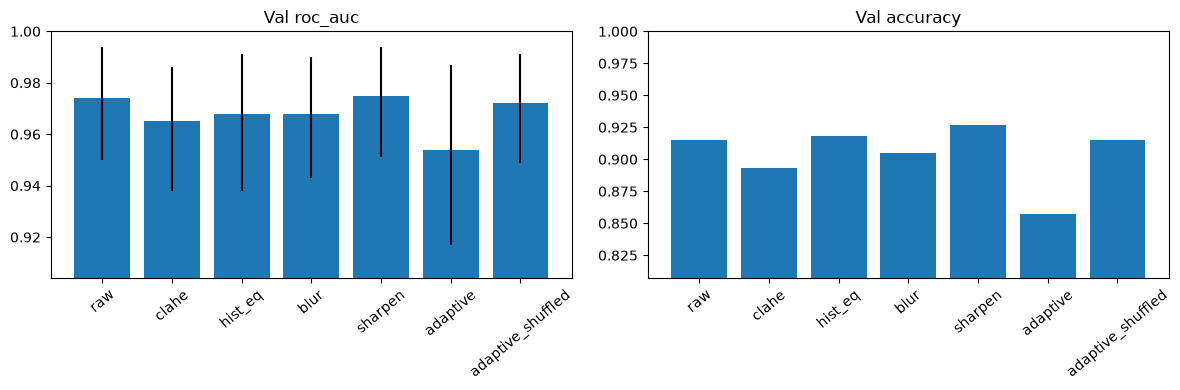

clahe              dAUC vs raw -0.010  95% CI [-0.026, +0.004]
hist_eq            dAUC vs raw -0.007  95% CI [-0.024, +0.008]
blur               dAUC vs raw -0.006  95% CI [-0.021, +0.008]
sharpen            dAUC vs raw +0.001  95% CI [-0.003, +0.005]
adaptive           dAUC vs raw -0.020  95% CI [-0.043, -0.003]
adaptive_shuffled  dAUC vs raw -0.002  95% CI [-0.014, +0.011]


In [12]:
# %% STEP 05: preprocessing experiments (run after step 04; same recipe, same seed per arm)
import matplotlib.pyplot as plt
REAL = ["raw", "clahe", "hist_eq", "blur", "sharpen", "adaptive"]
ARMS = REAL + ["adaptive_shuffled"]
cache = RES / "preproc"

# control: same method proportions as adaptive, but assigned at random (no labels used)
if not (cache / "adaptive_shuffled.npy").exists():
    ix = pd.read_csv(cache / "index.csv")
    Xs = {m: np.load(cache / f"{m}.npy", mmap_mode="r") for m in REAL[:5]}
    ch = np.random.default_rng(SEED).permutation(ix.adaptive_choice.values)
    out = np.empty(Xs["raw"].shape, np.uint8)
    for i, c in enumerate(ch): out[i] = Xs[c][i]
    np.save(cache / "adaptive_shuffled.npy", out)

results = {}
for a in ARMS:
    f = RES / f"val_mobilenetv2_{a}.json"
    if f.exists():
        results[a] = json.load(open(f))                    # skips arms already finished
    else:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)               # identical seed for every arm
        results[a] = run_arm(a, "mobilenetv2")

tab = pd.DataFrame([{**dict(arm=a), **{k: r[k] for k in ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc"]},
                     "auc_lo": r["ci95"]["roc_auc"][0], "auc_hi": r["ci95"]["roc_auc"][1]}
                    for a, r in results.items()]).round(3)
tab.to_csv(RES / "step05_val_comparison.csv", index=False)
print(tab.to_string(index=False))

# chart
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, col in zip(ax, ["roc_auc", "accuracy"]):
    a_.bar(tab.arm, tab[col]); a_.set_title(f"Val {col}"); a_.set_ylim(max(0, tab[col].min() - .05), 1)
    a_.tick_params(axis="x", rotation=40)
ax[0].errorbar(range(len(tab)), tab.roc_auc, yerr=[tab.roc_auc - tab.auc_lo, tab.auc_hi - tab.roc_auc], fmt="none", c="k")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "step05_comparison.png", dpi=120); plt.show()

# paired group-bootstrap difference vs raw (AUC)
sp = pd.read_csv(ROOT / "split.csv")[["path", "group"]]
vp = lambda a: pd.read_csv(RES / f"valpred_mobilenetv2_{a}.csv").merge(sp, on="path")
b = vp("raw"); ug = b.group.unique(); by = {g: np.where(b.group.values == g)[0] for g in ug}
rng = np.random.default_rng(SEED)
for a in ARMS[1:]:
    o = vp(a); assert (o.path.values == b.path.values).all()
    d = []
    for _ in range(1000):
        ii = np.concatenate([by[g] for g in rng.choice(ug, len(ug))])
        if len(np.unique(b.y.values[ii])) < 2: continue
        d.append(roc_auc_score(o.y.values[ii], o.p_cancer.values[ii]) - roc_auc_score(b.y.values[ii], b.p_cancer.values[ii]))
    print(f"{a:18s} dAUC vs raw {np.mean(d):+.3f}  95% CI [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]")

In [13]:
# %% STEP 06: EfficientNetB0 with Sharpening Preprocessing

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

MODEL_NAME = "efficientnetb0"
PREPROCESSING = "sharpen"

tf.keras.utils.set_random_seed(SEED)

print("=" * 65)
print("ONCOLENS - STEP 06: EFFICIENTNETB0")
print("=" * 65)

print(f"Model: {MODEL_NAME}")
print(f"Preprocessing: {PREPROCESSING}")
print(f"Random seed: {SEED}")

# --------------------------------------------------
# 2. Verify the existing split
# --------------------------------------------------

split_file = ROOT / "split.csv"

assert split_file.exists(), (
    f"Missing split file: {split_file}"
)

split_df = pd.read_csv(split_file)

required_columns = {"path", "group"}

assert required_columns.issubset(split_df.columns), (
    "split.csv must contain path and group columns."
)

assert split_df["path"].is_unique, (
    "Duplicate image paths detected in split.csv."
)

print("\nDataset split loaded successfully.")
print(f"Total image paths: {len(split_df)}")

if "split" in split_df.columns:
    print("\nSplit distribution:")
    print(split_df["split"].value_counts())

# --------------------------------------------------
# 3. Verify sharpening preprocessing cache
# --------------------------------------------------

cache_dir = RES / "preproc"

required_files = [
    cache_dir / "index.csv",
    cache_dir / "sharpen.npy"
]

for file in required_files:
    assert file.exists(), (
        f"Required preprocessing file not found: {file}"
    )

preproc_index = pd.read_csv(cache_dir / "index.csv")

sharpen_images = np.load(
    cache_dir / "sharpen.npy",
    mmap_mode="r"
)

assert len(preproc_index) == len(sharpen_images), (
    "Preprocessing index and image cache have different lengths."
)

print("\nSharpening preprocessing cache verified.")
print(f"Cached images: {len(sharpen_images)}")
print(f"Image shape: {sharpen_images.shape}")

# --------------------------------------------------
# 4. Train EfficientNetB0
# --------------------------------------------------

# Reuse the same training pipeline and recipe.
# This function must support EfficientNetB0.

result_file = RES / "val_efficientnetb0_sharpen.json"

if result_file.exists():
    print("\nExisting validation results found.")
    print("Loading saved results instead of retraining.")

    with open(result_file, "r", encoding="utf-8") as f:
        efficientnet_results = json.load(f)

else:
    print("\nStarting EfficientNetB0 training...")
    print("Stage 1: Training classification head")
    print("Stage 2: Fine-tuning the backbone")
    print("Evaluation: Validation set only")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    efficientnet_results = run_arm(
        PREPROCESSING,
        MODEL_NAME
    )

    # Preserve the results returned by the training pipeline.
    with open(result_file, "w", encoding="utf-8") as f:
        json.dump(
            efficientnet_results,
            f,
            indent=4,
            default=lambda x: (
                x.tolist() if isinstance(x, np.ndarray)
                else float(x) if isinstance(x, np.generic)
                else str(x)
            )
        )

# --------------------------------------------------
# 5. Display validation metrics
# --------------------------------------------------

metrics = [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "roc_auc"
]

print("\n" + "=" * 65)
print("EFFICIENTNETB0 - VALIDATION RESULTS")
print("=" * 65)

for metric in metrics:
    if metric in efficientnet_results:
        print(
            f"{metric.upper():15s}: "
            f"{efficientnet_results[metric]:.4f}"
        )

if "ci95" in efficientnet_results:
    if "roc_auc" in efficientnet_results["ci95"]:
        lo, hi = efficientnet_results["ci95"]["roc_auc"]

        print(f"ROC-AUC 95% CI: [{lo:.4f}, {hi:.4f}]")

print("\nValidation results saved to:")
print(result_file)

print("\nStep 06 training/evaluation pipeline finished.")

ONCOLENS - STEP 06: EFFICIENTNETB0
Model: efficientnetb0
Preprocessing: sharpen
Random seed: 42

Dataset split loaded successfully.
Total image paths: 2185

Split distribution:
split
train    1528
test      329
val       328
Name: count, dtype: int64

Sharpening preprocessing cache verified.
Cached images: 2180
Image shape: (2180, 224, 224, 3)

Starting EfficientNetB0 training...
Stage 1: Training classification head
Stage 2: Fine-tuning the backbone
Evaluation: Validation set only
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 9s 1us/step
Epoch 1/25


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 - 25s - 529ms/step - accuracy: 0.8310 - loss: 0.3723 - val_accuracy: 0.8963 - val_loss: 0.2223
Epoch 2/25
48/48 - 20s - 423ms/step - accuracy: 0.9194 - loss: 0.2125 - val_accuracy: 0.9177 - val_loss: 0.2232
Epoch 3/25
48/48 - 20s - 422ms/step - accuracy: 0.9384 - loss: 0.1652 - val_accuracy: 0.9238 - val_loss: 0.1826
Epoch 4/25
48/48 - 20s - 424ms/step - accuracy: 0.9515 - loss: 0.1247 - val_accuracy: 0.9238 - val_loss: 0.1874
Epoch 5/25
48/48 - 20s - 426ms/step - accuracy: 0.9607 - loss: 0.1173 - val_accuracy: 0.9329 - val_loss: 0.2063
Epoch 6/25
48/48 - 21s - 430ms/step - accuracy: 0.9633 - loss: 0.0992 - val_accuracy: 0.9360 - val_loss: 0.1725
Epoch 7/25
48/48 - 21s - 432ms/step - accuracy: 0.9738 - loss: 0.0722 - val_accuracy: 0.9543 - val_loss: 0.1816
Epoch 8/25
48/48 - 21s - 434ms/step - accuracy: 0.9666 - loss: 0.0785 - val_accuracy: 0.9299 - val_loss: 0.2045
Epoch 9/25
48/48 - 21s - 436ms/step - accuracy: 0.9777 - loss: 0.0673 - val_accuracy: 0.9360 - val_loss: 0.2040
Epo


VALIDATION COMPARISON
     Metric  MobileNetV2  EfficientNetB0  Difference
   accuracy       0.9268          0.9665      0.0396
  precision       0.9425          0.9665      0.0240
     recall       0.9213          0.9719      0.0506
specificity       0.9333          0.9600      0.0267
         f1       0.9318          0.9692      0.0374
    roc_auc       0.9751          0.9840      0.0089

Comparison saved to: C:\Users\Bhavana BV\Downloads\OncoLens\results\step06_model_comparison.csv


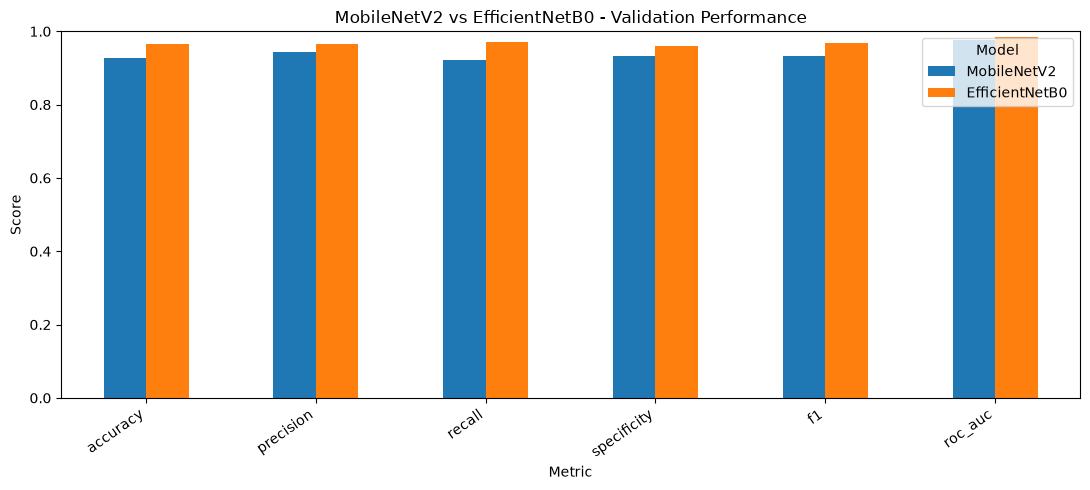

Comparison chart saved to: C:\Users\Bhavana BV\Downloads\OncoLens\figures\step06_model_comparison.png


In [14]:
# %% STEP 06: MobileNetV2 vs EfficientNetB0

import json
import pandas as pd
import matplotlib.pyplot as plt

mobile_file = RES / "val_mobilenetv2_sharpen.json"
efficient_file = RES / "val_efficientnetb0_sharpen.json"

assert mobile_file.exists(), (
    "MobileNetV2 sharpening validation results are missing."
)

assert efficient_file.exists(), (
    "EfficientNetB0 sharpening validation results are missing."
)

with open(mobile_file, "r", encoding="utf-8") as f:
    mobile_results = json.load(f)

with open(efficient_file, "r", encoding="utf-8") as f:
    efficient_results = json.load(f)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "roc_auc"
]

comparison = pd.DataFrame({
    "Metric": metrics,
    "MobileNetV2": [
        mobile_results[m] for m in metrics
    ],
    "EfficientNetB0": [
        efficient_results[m] for m in metrics
    ]
})

comparison["Difference"] = (
    comparison["EfficientNetB0"]
    - comparison["MobileNetV2"]
)

print("\nVALIDATION COMPARISON")
print("=" * 75)
print(comparison.round(4).to_string(index=False))

comparison_file = RES / "step06_model_comparison.csv"

comparison.to_csv(
    comparison_file,
    index=False
)

print(f"\nComparison saved to: {comparison_file}")

# Plot comparison

ax = comparison.set_index("Metric")[
    ["MobileNetV2", "EfficientNetB0"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title(
    "MobileNetV2 vs EfficientNetB0 - Validation Performance"
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("Metric")
ax.legend(title="Model")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

figure_file = ROOT / "figures" / "step06_model_comparison.png"

figure_file.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    figure_file,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(f"Comparison chart saved to: {figure_file}")

In [15]:
# %% STEP 06: FINAL DATA AND MODEL CHECK

import pandas as pd
import numpy as np
from pathlib import Path

split_file = ROOT / "split.csv"
cache_dir = RES / "preproc"
index_file = cache_dir / "index.csv"

split_df = pd.read_csv(split_file)
index_df = pd.read_csv(index_file)

print("=" * 60)
print("ONCOLENS: STEP 06 VERIFICATION")
print("=" * 60)

print("\n1. SPLIT SUMMARY")
print(split_df["split"].value_counts())

print("\nTotal split rows:", len(split_df))
print("Unique split paths:", split_df["path"].nunique())

print("\n2. PREPROCESSING CACHE")

print("Cache index rows:", len(index_df))
print("Unique cache paths:", index_df["path"].nunique())

sharpen_file = cache_dir / "sharpen.npy"
sharpen = np.load(sharpen_file, mmap_mode="r")

print("Sharpening image count:", len(sharpen))
print("Sharpening image shape:", sharpen.shape)

print("\n3. MISSING IMAGE PATHS")

split_paths = set(split_df["path"].astype(str))
cache_paths = set(index_df["path"].astype(str))

missing = split_paths - cache_paths
extra = cache_paths - split_paths

print("Paths missing from cache:", len(missing))
print("Extra cache paths:", len(extra))

if missing:
    print("\nFirst missing paths:")
    for p in sorted(missing)[:10]:
        print(p)

print("\n4. SAVED MODEL FILES")

for folder in [
    ROOT / "checkpoints",
    RES
]:
    print(f"\n{folder}")

    if folder.exists():
        files = [
            p for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in {
                ".keras", ".h5", ".weights", ".index"
            }
        ]

        if files:
            for p in files:
                print(" ", p)
        else:
            print("  No matching model files found.")
    else:
        print("  Folder does not exist.")

print("\nVerification finished.")

ONCOLENS: STEP 06 VERIFICATION

1. SPLIT SUMMARY
split
train    1528
test      329
val       328
Name: count, dtype: int64

Total split rows: 2185
Unique split paths: 2185

2. PREPROCESSING CACHE
Cache index rows: 2180
Unique cache paths: 2180
Sharpening image count: 2180
Sharpening image shape: (2180, 224, 224, 3)

3. MISSING IMAGE PATHS
Paths missing from cache: 5
Extra cache paths: 0

First missing paths:
cancer/D1_Cancer_0040.jpeg
cancer/D2_Cancer_0041.jpeg
cancer/D2_Cancer_0533.png
cancer/D2_Cancer_0598.jpg
non_cancer/D2_NonCancer_0138.png

4. SAVED MODEL FILES

C:\Users\Bhavana BV\Downloads\OncoLens\checkpoints
  C:\Users\Bhavana BV\Downloads\OncoLens\checkpoints\efficientnetb0_sharpen.keras
  C:\Users\Bhavana BV\Downloads\OncoLens\checkpoints\mobilenetv2_adaptive.keras
  C:\Users\Bhavana BV\Downloads\OncoLens\checkpoints\mobilenetv2_adaptive_shuffled.keras
  C:\Users\Bhavana BV\Downloads\OncoLens\checkpoints\mobilenetv2_blur.keras
  C:\Users\Bhavana BV\Downloads\OncoLens\checkpo

In [16]:
# %% STEP 06A: INVESTIGATE THE FIVE MISSING IMAGES

from pathlib import Path
from PIL import Image
import pandas as pd

split_df = pd.read_csv(ROOT / "split.csv")
index_df = pd.read_csv(RES / "preproc" / "index.csv")

missing_paths = [
    "cancer/D1_Cancer_0040.jpeg",
    "cancer/D2_Cancer_0041.jpeg",
    "cancer/D2_Cancer_0533.png",
    "cancer/D2_Cancer_0598.jpg",
    "non_cancer/D2_NonCancer_0138.png",
]

# Find the dataset root using paths already present in split.csv.
# Adjust DATASET_ROOT if your dataset has a different directory.
DATASET_ROOT = ROOT / "dataset"

print("=" * 70)
print("MISSING IMAGE INVESTIGATION")
print("=" * 70)

print("\nDataset root:", DATASET_ROOT)
print("Dataset root exists:", DATASET_ROOT.exists())

for relative_path in missing_paths:

    image_path = DATASET_ROOT / relative_path

    print(f"\nImage: {relative_path}")
    print("Exists:", image_path.exists())

    if image_path.exists():
        try:
            with Image.open(image_path) as img:
                img.verify()

            with Image.open(image_path) as img:
                print("Image size:", img.size)
                print("Image mode:", img.mode)
                print("Image verification: PASS")

        except Exception as exc:
            print("Image verification: FAIL")
            print("Error:", repr(exc))

    row = split_df.loc[
        split_df["path"].astype(str) == relative_path
    ]

    if len(row):
        print("Split:", row.iloc[0]["split"])
        print("Group:", row.iloc[0]["group"])
    else:
        print("WARNING: Image not found in split.csv")

    cache_row = index_df.loc[
        index_df["path"].astype(str) == relative_path
    ]

    print("Present in preprocessing index:", len(cache_row) > 0)

print("\nInvestigation complete. No files were modified.")

MISSING IMAGE INVESTIGATION

Dataset root: C:\Users\Bhavana BV\Downloads\OncoLens\dataset
Dataset root exists: True

Image: cancer/D1_Cancer_0040.jpeg
Exists: True
Image size: (1233, 834)
Image mode: RGB
Image verification: PASS
Split: test
Group: 39
Present in preprocessing index: False

Image: cancer/D2_Cancer_0041.jpeg
Exists: True
Image size: (1233, 834)
Image mode: RGB
Image verification: PASS
Split: test
Group: 39
Present in preprocessing index: False

Image: cancer/D2_Cancer_0533.png
Exists: True
Image size: (1233, 834)
Image mode: RGB
Image verification: PASS
Split: test
Group: 39
Present in preprocessing index: False

Image: cancer/D2_Cancer_0598.jpg
Exists: True
Image size: (250, 168)
Image mode: RGB
Image verification: PASS
Split: train
Group: 509
Present in preprocessing index: False

Image: non_cancer/D2_NonCancer_0138.png
Exists: True
Image size: (1233, 834)
Image mode: RGB
Image verification: PASS
Split: test
Group: 39
Present in preprocessing index: False

Investigation

In [18]:
# %% STEP 06B: AUDIT DATASET AND PREPROCESSING INDEX

from pathlib import Path
import pandas as pd

DATASET_ROOT = ROOT / "dataset"
CACHE_DIR = RES / "preproc"

split_df = pd.read_csv(ROOT / "split.csv")
index_df = pd.read_csv(CACHE_DIR / "index.csv")

# Collect image paths from the original dataset.
extensions = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

disk_paths = {
    p.relative_to(DATASET_ROOT).as_posix()
    for p in DATASET_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
}

split_paths = set(
    split_df["path"].astype(str).str.replace("\\", "/", regex=False)
)

cache_paths = set(
    index_df["path"].astype(str).str.replace("\\", "/", regex=False)
)

print("=" * 70)
print("ONCOLENS DATASET AUDIT")
print("=" * 70)

print("\nOriginal dataset image count:", len(disk_paths))
print("Saved split image count:", len(split_paths))
print("Preprocessing index count:", len(cache_paths))

print("\nImages on disk but absent from split:")
print(sorted(disk_paths - split_paths)[:20])
print("Count:", len(disk_paths - split_paths))

print("\nImages in split but absent from disk:")
print(sorted(split_paths - disk_paths)[:20])
print("Count:", len(split_paths - disk_paths))

print("\nImages in split but absent from preprocessing index:")
missing_cache = split_paths - cache_paths
print(sorted(missing_cache))
print("Count:", len(missing_cache))

print("\nImages in preprocessing index but absent from split:")
extra_cache = cache_paths - split_paths
print(sorted(extra_cache)[:20])
print("Count:", len(extra_cache))

print("\nIndex columns:")
print(index_df.columns.tolist())

print("\nFirst five index rows:")
print(index_df.head().to_string(index=False))

print("\nAudit complete. No files were modified.")

ONCOLENS DATASET AUDIT

Original dataset image count: 2185
Saved split image count: 2185
Preprocessing index count: 2180

Images on disk but absent from split:
[]
Count: 0

Images in split but absent from disk:
[]
Count: 0

Images in split but absent from preprocessing index:
['cancer/D1_Cancer_0040.jpeg', 'cancer/D2_Cancer_0041.jpeg', 'cancer/D2_Cancer_0533.png', 'cancer/D2_Cancer_0598.jpg', 'non_cancer/D2_NonCancer_0138.png']
Count: 5

Images in preprocessing index but absent from split:
[]
Count: 0

Index columns:
['path', 'split', 'y', 'adaptive_choice', 'contrast', 'brightness', 'sharpness', 'noise']

First five index rows:
                      path split  y adaptive_choice  contrast  brightness  sharpness    noise
cancer/D1_Cancer_0001.jpeg train  1             raw 49.894787  136.489822 271.114410 0.963661
cancer/D1_Cancer_0002.jpeg train  1         sharpen 78.486504  120.083588  58.537270 0.486828
cancer/D1_Cancer_0003.jpeg train  1         sharpen 41.873657  128.209564  31.608

In [19]:
# %% STEP 06C: REBUILD PREPROCESSING CACHE
# Does not modify split.csv or evaluate the test set.

import hashlib
import shutil
import cv2
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image

# --------------------------------------------------
# 1. Paths and configuration
# --------------------------------------------------

DATASET_ROOT = ROOT / "dataset"
CACHE_DIR = RES / "preproc"
SPLIT_FILE = ROOT / "split.csv"

assert DATASET_ROOT.exists()
assert SPLIT_FILE.exists()

split_df = pd.read_csv(SPLIT_FILE)

assert len(split_df) == 2185
assert split_df["path"].is_unique

# Backup the existing cache before rebuilding.
BACKUP_DIR = RES / "preproc_backup_before_repair"

if not BACKUP_DIR.exists():
    shutil.copytree(CACHE_DIR, BACKUP_DIR)

print("Existing cache backed up to:", BACKUP_DIR)

# --------------------------------------------------
# 2. Preserve the exact original split
# --------------------------------------------------

split_df["path"] = (
    split_df["path"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
)

split_map = split_df.set_index("path")["split"].to_dict()

# Use the saved split's exact path order.
paths = split_df["path"].tolist()

# Confirm every image exists.
missing_on_disk = [
    p for p in paths
    if not (DATASET_ROOT / Path(p)).is_file()
]

assert not missing_on_disk, (
    f"Images missing on disk: {missing_on_disk[:10]}"
)

# --------------------------------------------------
# 3. Preprocessing functions
# --------------------------------------------------

def preprocess_image(image_path, method):
    """Load RGB image, resize to 224x224, apply preprocessing."""

    with Image.open(image_path) as im:
        im = im.convert("RGB")
        im = im.resize((224, 224), Image.Resampling.LANCZOS)
        img = np.asarray(im, dtype=np.uint8)

    if method == "raw":
        result = img

    elif method == "clahe":
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        l = clahe.apply(l)
        result = cv2.cvtColor(
            cv2.merge((l, a, b)),
            cv2.COLOR_LAB2RGB
        )

    elif method == "hist_eq":
        ycrcb = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
        y, cr, cb = cv2.split(ycrcb)

        y = cv2.equalizeHist(y)

        result = cv2.cvtColor(
            cv2.merge((y, cr, cb)),
            cv2.COLOR_YCrCb2RGB
        )

    elif method == "blur":
        result = cv2.GaussianBlur(
            img,
            (3, 3),
            sigmaX=0
        )

    elif method == "sharpen":
        blurred = cv2.GaussianBlur(
            img,
            (0, 0),
            sigmaX=1.0
        )

        result = cv2.addWeighted(
            img,
            1.5,
            blurred,
            -0.5,
            0
        )

    else:
        raise ValueError(f"Unknown preprocessing method: {method}")

    return np.clip(result, 0, 255).astype(np.uint8)


def image_statistics(img):
    """Calculate simple image-quality statistics."""

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    contrast = float(np.std(gray))
    brightness = float(np.mean(gray))
    sharpness = float(cv2.Laplacian(
        gray, cv2.CV_64F
    ).var())

    noise = float(np.mean(
        np.abs(
            gray.astype(np.float32)
            - cv2.GaussianBlur(
                gray, (3, 3), 0
            ).astype(np.float32)
        )
    ))

    return contrast, brightness, sharpness, noise


def choose_adaptive_method(contrast, brightness, sharpness, noise):
    """
    Deterministic image-quality heuristic.
    This does not use cancer labels.
    """

    if contrast < 35:
        return "clahe"

    if brightness < 75 or brightness > 185:
        return "hist_eq"

    if sharpness < 35:
        return "sharpen"

    if noise > 15:
        return "blur"

    return "raw"


# --------------------------------------------------
# 4. Rebuild arrays in the same exact order
# --------------------------------------------------

methods = [
    "raw",
    "clahe",
    "hist_eq",
    "blur",
    "sharpen"
]

arrays = {
    method: np.empty(
        (len(paths), 224, 224, 3),
        dtype=np.uint8
    )
    for method in methods
}

records = []

print("\nReprocessing", len(paths), "images...")

for i, relative_path in enumerate(paths):

    image_path = DATASET_ROOT / Path(relative_path)

    raw = preprocess_image(image_path, "raw")

    contrast, brightness, sharpness, noise = (
        image_statistics(raw)
    )

    adaptive_choice = choose_adaptive_method(
        contrast,
        brightness,
        sharpness,
        noise
    )

    for method in methods:
        if method == "raw":
            arrays[method][i] = raw
        else:
            arrays[method][i] = preprocess_image(
                image_path,
                method
            )

    records.append({
        "path": relative_path,
        "split": split_map[relative_path],
        "y": (
            1 if relative_path.split("/")[0] == "cancer"
            else 0
        ),
        "adaptive_choice": adaptive_choice,
        "contrast": contrast,
        "brightness": brightness,
        "sharpness": sharpness,
        "noise": noise
    })

    if (i + 1) % 250 == 0:
        print(f"Processed {i + 1}/{len(paths)} images")

# Adaptive preprocessing: choose the appropriate cached method.
method_to_index = {
    method: j for j, method in enumerate(methods)
}

adaptive = np.empty_like(arrays["raw"])

for i, row in enumerate(records):
    selected_method = row["adaptive_choice"]

    adaptive[i] = arrays[selected_method][i]

# --------------------------------------------------
# 5. Save cache
# --------------------------------------------------

CACHE_DIR.mkdir(parents=True, exist_ok=True)

for method, array in arrays.items():
    np.save(
        CACHE_DIR / f"{method}.npy",
        array
    )

np.save(
    CACHE_DIR / "adaptive.npy",
    adaptive
)

index_df = pd.DataFrame(records)

index_df.to_csv(
    CACHE_DIR / "index.csv",
    index=False
)

# --------------------------------------------------
# 6. Verify complete coverage
# --------------------------------------------------

saved_index = pd.read_csv(
    CACHE_DIR / "index.csv"
)

assert len(saved_index) == 2185
assert saved_index["path"].is_unique
assert set(saved_index["path"]) == set(paths)

for method in methods + ["adaptive"]:
    arr = np.load(
        CACHE_DIR / f"{method}.npy",
        mmap_mode="r"
    )

    assert arr.shape == (2185, 224, 224, 3)

print("\n" + "=" * 65)
print("PREPROCESSING CACHE REPAIR COMPLETE")
print("=" * 65)

print("Original split preserved:", SPLIT_FILE)
print("Images indexed:", len(saved_index))
print("Unique paths:", saved_index["path"].nunique())

print("\nSplit distribution:")
print(saved_index["split"].value_counts())

print("\nArray shapes:")
for method in methods + ["adaptive"]:
    arr = np.load(
        CACHE_DIR / f"{method}.npy",
        mmap_mode="r"
    )
    print(f"{method:12s}: {arr.shape}")

print("\nBackup location:", BACKUP_DIR)
print("No model training or test evaluation was performed.")

Existing cache backed up to: C:\Users\Bhavana BV\Downloads\OncoLens\results\preproc_backup_before_repair

Reprocessing 2185 images...


c:\Users\Bhavana BV\Downloads\OncoLens\.venv\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Processed 250/2185 images
Processed 500/2185 images
Processed 750/2185 images
Processed 1000/2185 images
Processed 1250/2185 images
Processed 1500/2185 images
Processed 1750/2185 images
Processed 2000/2185 images


OSError: [Errno 22] Invalid argument: 'C:\\Users\\Bhavana BV\\Downloads\\OncoLens\\results\\preproc\\raw.npy'

In [20]:
from pathlib import Path
import os

print("ROOT:", repr(str(ROOT)))
print("RES:", repr(str(RES)))

CACHE_DIR = Path(RES) / "preproc"

print("CACHE_DIR:", repr(str(CACHE_DIR)))
print("Path exists:", CACHE_DIR.exists())
print("Is directory:", CACHE_DIR.is_dir())

# Check the parent directory
print("Results directory exists:", Path(RES).exists())
print("Results is directory:", Path(RES).is_dir())

# Check whether raw.npy already exists
raw_path = CACHE_DIR / "raw.npy"
print("Raw file path:", repr(str(raw_path)))
print("Raw file exists:", raw_path.exists())

# Test whether Windows can write to this directory
CACHE_DIR.mkdir(parents=True, exist_ok=True)

test_file = CACHE_DIR / "write_test.tmp"

try:
    test_file.write_text("write test", encoding="utf-8")
    print("WRITE TEST: SUCCESS")
    test_file.unlink()
except Exception as e:
    print("WRITE TEST FAILED:", repr(e))

ROOT: 'C:\\Users\\Bhavana BV\\Downloads\\OncoLens'
RES: 'C:\\Users\\Bhavana BV\\Downloads\\OncoLens\\results'
CACHE_DIR: 'C:\\Users\\Bhavana BV\\Downloads\\OncoLens\\results\\preproc'
Path exists: True
Is directory: True
Results directory exists: True
Results is directory: True
Raw file path: 'C:\\Users\\Bhavana BV\\Downloads\\OncoLens\\results\\preproc\\raw.npy'
Raw file exists: True
WRITE TEST: SUCCESS


In [21]:
import numpy as np

test_npy = CACHE_DIR / "numpy_write_test.npy"

try:
    np.save(test_npy, np.zeros((2, 2), dtype=np.uint8))
    loaded = np.load(test_npy)

    print("NUMPY SAVE TEST: SUCCESS")
    print("Test array shape:", loaded.shape)

    test_npy.unlink()

except Exception as e:
    print("NUMPY SAVE TEST FAILED:", repr(e))

NUMPY SAVE TEST: SUCCESS
Test array shape: (2, 2)


In [22]:
from pathlib import Path
import os
import numpy as np

CACHE_DIR = Path(RES) / "preproc"

print("=== CACHE DIRECTORY INSPECTION ===")

for p in sorted(CACHE_DIR.iterdir()):
    try:
        print(
            f"Name: {p.name} | "
            f"Directory: {p.is_dir()} | "
            f"Size: {p.stat().st_size if p.is_file() else 'N/A'} bytes"
        )
    except OSError as e:
        print(f"Could not inspect {p.name}: {e}")

print("\n=== RAW.NPY INSPECTION ===")

raw_path = CACHE_DIR / "raw.npy"

if raw_path.exists() and raw_path.is_file():
    try:
        arr = np.load(raw_path, mmap_mode="r", allow_pickle=False)
        print("File can be loaded:", True)
        print("Shape:", arr.shape)
        print("Data type:", arr.dtype)
    except Exception as e:
        print("File loading failed:", repr(e))
elif raw_path.exists():
    print("ERROR: raw.npy exists but is not a regular file.")
else:
    print("raw.npy does not exist.")

=== CACHE DIRECTORY INSPECTION ===
Name: adaptive.npy | Directory: False | Size: 328151168 bytes
Name: adaptive_shuffled.npy | Directory: False | Size: 328151168 bytes
Name: blur.npy | Directory: False | Size: 328151168 bytes
Name: clahe.npy | Directory: False | Size: 328151168 bytes
Name: hist_eq.npy | Directory: False | Size: 328151168 bytes
Name: index.csv | Directory: False | Size: 256900 bytes
Name: raw.npy | Directory: False | Size: 328151168 bytes
Name: sharpen.npy | Directory: False | Size: 328151168 bytes

=== RAW.NPY INSPECTION ===
File can be loaded: True
Shape: (2180, 224, 224, 3)
Data type: uint8


In [23]:
from pathlib import Path
import pandas as pd
import numpy as np

CACHE_DIR = Path(RES) / "preproc"
SPLIT_FILE = Path(ROOT) / "split.csv"
INDEX_FILE = CACHE_DIR / "index.csv"

# Load the existing split and cache index
split_df = pd.read_csv(SPLIT_FILE)
index_df = pd.read_csv(INDEX_FILE)

# Normalize paths for reliable comparison on Windows
split_paths = set(
    split_df["path"].astype(str).str.replace("\\", "/", regex=False)
)

index_paths = set(
    index_df["path"].astype(str).str.replace("\\", "/", regex=False)
)

missing_paths = sorted(split_paths - index_paths)

print("Images in split.csv:", len(split_df))
print("Unique split paths:", len(split_paths))
print("Images in cache index:", len(index_df))
print("Missing cache entries:", len(missing_paths))

print("\nMissing paths:")
for p in missing_paths:
    print(" -", p)

print("\nExisting cache arrays:")
for method in [
    "raw", "clahe", "hist_eq", "blur",
    "sharpen", "adaptive", "adaptive_shuffled"
]:
    file_path = CACHE_DIR / f"{method}.npy"
    if file_path.exists():
        arr = np.load(file_path, mmap_mode="r", allow_pickle=False)
        print(f"{method}: {arr.shape}")

Images in split.csv: 2185
Unique split paths: 2185
Images in cache index: 2180
Missing cache entries: 5

Missing paths:
 - cancer/D1_Cancer_0040.jpeg
 - cancer/D2_Cancer_0041.jpeg
 - cancer/D2_Cancer_0533.png
 - cancer/D2_Cancer_0598.jpg
 - non_cancer/D2_NonCancer_0138.png

Existing cache arrays:
raw: (2180, 224, 224, 3)
clahe: (2180, 224, 224, 3)
hist_eq: (2180, 224, 224, 3)
blur: (2180, 224, 224, 3)
sharpen: (2180, 224, 224, 3)
adaptive: (2180, 224, 224, 3)
adaptive_shuffled: (2180, 224, 224, 3)


In [25]:
import inspect

source = inspect.getsource(run_arm)

for i, line in enumerate(source.splitlines(), start=1):
    if any(term in line.lower() for term in [
        "index", "cache", "npy", "split", "label",
        "y_train", "y_val", "shuffle", "load"
    ]):
        print(f"{i:03}: {line}")

002:     X, idx = load_arm(method)
003:     tr, va = (idx.split == "train").values, (idx.split == "val").values   # test is never loaded here
006:     dtr = tf.data.Dataset.from_tensor_slices((Xtr, ytr)).shuffle(len(Xtr), seed=SEED).batch(BATCH).prefetch(2)
028:     pd.DataFrame(dict(path=idx.path[va].values, y=yva, p_cancer=p)).to_csv(RES / f"valpred_{tag}.csv", index=False)


In [26]:
import pandas as pd
from pathlib import Path

split_df = pd.read_csv(Path(ROOT) / "split.csv")

missing_paths = [
    "cancer/D1_Cancer_0040.jpeg",
    "cancer/D2_Cancer_0041.jpeg",
    "cancer/D2_Cancer_0533.png",
    "cancer/D2_Cancer_0598.jpg",
    "non_cancer/D2_NonCancer_0138.png",
]

normalized_paths = (
    split_df["path"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
)

for path in missing_paths:
    rows = split_df.loc[normalized_paths == path]
    print(f"\n{path}")
    print(rows.to_string(index=False) if not rows.empty else "NOT FOUND")


cancer/D1_Cancer_0040.jpeg
                      path  label    w   h                              md5            phash  group split  label_id   use
cancer/D1_Cancer_0040.jpeg cancer 1233 834 36685be30465b516867c5ed197c8d183 f5b6c218d8b90877     39  test         1 False

cancer/D2_Cancer_0041.jpeg
                      path  label    w   h                              md5            phash  group split  label_id   use
cancer/D2_Cancer_0041.jpeg cancer 1233 834 36685be30465b516867c5ed197c8d183 f5b6c218d8b90877     39  test         1 False

cancer/D2_Cancer_0533.png
                     path  label    w   h                              md5            phash  group split  label_id   use
cancer/D2_Cancer_0533.png cancer 1233 834 36685be30465b516867c5ed197c8d183 f5b6c218d8b90877     39  test         1 False

cancer/D2_Cancer_0598.jpg
                     path  label   w   h                              md5            phash  group split  label_id   use
cancer/D2_Cancer_0598.jpg cancer 250 168

In [27]:
import inspect

print(inspect.getsource(load_arm))

def load_arm(method):
    idx = pd.read_csv(RES / "preproc" / "index.csv")
    X = np.load(RES / "preproc" / f"{method}.npy")
    grp = pd.read_csv(ROOT / "split.csv")[["path", "group"]]
    idx = idx.merge(grp, on="path", how="left")
    assert len(idx) == len(X) and idx.group.notna().all()
    return X, idx



In [28]:
import pandas as pd
from pathlib import Path

split_df = pd.read_csv(Path(ROOT) / "split.csv")
index_df = pd.read_csv(Path(RES) / "preproc" / "index.csv")

print("=== SPLIT COLUMNS ===")
print(split_df.columns.tolist())

print("\n=== CACHE INDEX COLUMNS ===")
print(index_df.columns.tolist())

print("\n=== SPLIT USAGE SUMMARY ===")
print(split_df.groupby(["split", "use"], dropna=False).size())

print("\n=== LABEL COUNTS ===")
print(
    split_df.groupby(
        ["split", "label", "use"], dropna=False
    ).size()
)

print("\n=== GROUP 39 DUPLICATES ===")
print(
    split_df.loc[
        split_df["group"] == 39,
        ["path", "label", "md5", "group", "split", "use"]
    ].to_string(index=False)
)

print("\n=== CACHE INDEX EXCLUSION COLUMNS ===")
for col in ["path", "split", "y", "adaptive_choice"]:
    if col in index_df.columns:
        print(f"\n{col}:")
        print(index_df[col].head(3).to_list())

=== SPLIT COLUMNS ===
['path', 'label', 'w', 'h', 'md5', 'phash', 'group', 'split', 'label_id', 'use']

=== CACHE INDEX COLUMNS ===
['path', 'split', 'y', 'adaptive_choice', 'contrast', 'brightness', 'sharpness', 'noise']

=== SPLIT USAGE SUMMARY ===
split  use  
test   False       4
       True      325
train  False       1
       True     1527
val    True      328
dtype: int64

=== LABEL COUNTS ===
split  label       use  
test   cancer      False      3
                   True     175
       non_cancer  False      1
                   True     150
train  cancer      False      1
                   True     827
       non_cancer  True     700
val    cancer      True     178
       non_cancer  True     150
dtype: int64

=== GROUP 39 DUPLICATES ===
                            path      label                              md5  group split   use
      cancer/D1_Cancer_0040.jpeg     cancer 36685be30465b516867c5ed197c8d183     39  test False
      cancer/D2_Cancer_0041.jpeg     cancer 36685

In [29]:
import pandas as pd
import numpy as np
from pathlib import Path

split_df = pd.read_csv(Path(ROOT) / "split.csv")
index_df = pd.read_csv(Path(RES) / "preproc" / "index.csv")

CACHE_DIR = Path(RES) / "preproc"

# Expected eligible images
eligible = split_df.loc[split_df["use"] == True].copy()

# Normalize paths for Windows
eligible_paths = set(
    eligible["path"].astype(str).str.replace("\\", "/", regex=False)
)

cached_paths = set(
    index_df["path"].astype(str).str.replace("\\", "/", regex=False)
)

print("=== CACHE VALIDATION ===")
print("Eligible images:", len(eligible))
print("Cached index rows:", len(index_df))
print("Unique eligible paths:", len(eligible_paths))
print("Unique cached paths:", len(cached_paths))
print("Missing eligible paths:", len(eligible_paths - cached_paths))
print("Unexpected cached paths:", len(cached_paths - eligible_paths))

print("\n=== ARRAY VALIDATION ===")

for method in [
    "raw",
    "clahe",
    "hist_eq",
    "blur",
    "sharpen",
    "adaptive",
    "adaptive_shuffled",
]:
    array_path = CACHE_DIR / f"{method}.npy"

    if not array_path.exists():
        print(f"{method}: MISSING")
        continue

    arr = np.load(array_path, mmap_mode="r", allow_pickle=False)

    print(f"{method}: shape={arr.shape}, dtype={arr.dtype}")

    assert len(arr) == len(index_df), (
        f"{method}: array/index length mismatch"
    )

assert len(eligible_paths) == len(cached_paths)
assert eligible_paths == cached_paths
assert index_df["path"].is_unique

print("\nPASS: Cache contains exactly the eligible image paths.")

=== CACHE VALIDATION ===
Eligible images: 2180
Cached index rows: 2180
Unique eligible paths: 2180
Unique cached paths: 2180
Missing eligible paths: 0
Unexpected cached paths: 0

=== ARRAY VALIDATION ===
raw: shape=(2180, 224, 224, 3), dtype=uint8
clahe: shape=(2180, 224, 224, 3), dtype=uint8
hist_eq: shape=(2180, 224, 224, 3), dtype=uint8
blur: shape=(2180, 224, 224, 3), dtype=uint8
sharpen: shape=(2180, 224, 224, 3), dtype=uint8
adaptive: shape=(2180, 224, 224, 3), dtype=uint8
adaptive_shuffled: shape=(2180, 224, 224, 3), dtype=uint8

PASS: Cache contains exactly the eligible image paths.


In [30]:
import inspect

print(inspect.getsource(run_arm))

def run_arm(method, backbone="mobilenetv2"):
    X, idx = load_arm(method)
    tr, va = (idx.split == "train").values, (idx.split == "val").values   # test is never loaded here
    Xtr, ytr, Xva, yva = X[tr], idx.y.values[tr], X[va], idx.y.values[va]
    cw = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr)))
    dtr = tf.data.Dataset.from_tensor_slices((Xtr, ytr)).shuffle(len(Xtr), seed=SEED).batch(BATCH).prefetch(2)
    dva = tf.data.Dataset.from_tensor_slices((Xva, yva)).batch(BATCH).prefetch(2)

    m, base = build(backbone); tag = f"{backbone}_{method}"
    es = lambda: tf.keras.callbacks.EarlyStopping("val_loss", patience=5, restore_best_weights=True)

    compile_(m, 1e-3)                                                      # stage 1: head only
    h1 = m.fit(dtr, validation_data=dva, epochs=25, class_weight=cw, callbacks=[es()], verbose=2)

    base.trainable = True                                                  # stage 2: last ~30 layers
    

In [32]:
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedGroupKFold

# Load the original dataset manifest
split_df = pd.read_csv(Path(ROOT) / "split.csv")

# Keep only eligible training and validation images
dev = split_df.loc[
    split_df["use"].astype(bool)
    & split_df["split"].isin(["train", "val"])
].copy()

dev["path"] = (
    dev["path"].astype(str).str.replace("\\", "/", regex=False)
)

# Verify the expected development dataset
print("Development images:", len(dev))
print("Development groups:", dev["group"].nunique())
print("\nOriginal split counts:")
print(dev["split"].value_counts())

# Verify that each group belongs to exactly one original split
groups_per_split = dev.groupby("group")["split"].nunique()

assert groups_per_split.max() == 1, (
    "A group appears in multiple original splits. Investigate before CV."
)

# Create reproducible group-aware folds
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

dev = dev.reset_index(drop=True)
dev["fold"] = -1

for fold, (_, val_idx) in enumerate(
    cv.split(
        X=np.zeros(len(dev)),
        y=dev["label_id"].astype(int),
        groups=dev["group"]
    )
):
    dev.loc[val_idx, "fold"] = fold

# Verify every development image received one fold
assert (dev["fold"] >= 0).all()

# Verify no group crosses folds
assert dev.groupby("group")["fold"].nunique().max() == 1

# Summarize fold composition
print("\n=== FOLD SUMMARY ===")

for fold in range(5):
    fold_df = dev[dev["fold"] == fold]

    print(
        f"Fold {fold}: "
        f"images={len(fold_df)}, "
        f"groups={fold_df['group'].nunique()}, "
        f"cancer={(fold_df['label_id'] == 1).sum()}, "
        f"non_cancer={(fold_df['label_id'] == 0).sum()}"
    )

# Save fold assignments separately; do not modify split.csv
fold_file = Path(RES) / "cv5_group_fold_assignments.csv"
fold_file.parent.mkdir(parents=True, exist_ok=True)

dev[
    ["path", "label", "label_id", "group", "split", "fold"]
].to_csv(fold_file, index=False)

print("\nSaved fold assignments to:", fold_file)
print("Original split.csv remains unchanged.")

Development images: 1855
Development groups: 930

Original split counts:
split
train    1527
val       328
Name: count, dtype: int64

=== FOLD SUMMARY ===
Fold 0: images=371, groups=186, cancer=201, non_cancer=170
Fold 1: images=371, groups=185, cancer=201, non_cancer=170
Fold 2: images=371, groups=187, cancer=201, non_cancer=170
Fold 3: images=371, groups=186, cancer=201, non_cancer=170
Fold 4: images=371, groups=186, cancer=201, non_cancer=170

Saved fold assignments to: C:\Users\Bhavana BV\Downloads\OncoLens\results\cv5_group_fold_assignments.csv
Original split.csv remains unchanged.
